<a href="https://colab.research.google.com/github/msbangash/mlproject_1/blob/main/mlproject_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Installing Python Libraries
To install a new Python library in Colab, run a cell with `!pip install <library_name>`. For example:

In [ ]:
!pip install requests

### Importing Top AI Libraries
Let's import these popular AI libraries to make sure they are installed and ready to use in the notebook.

In [1]:
import torch
import tensorflow as tf
import sklearn
from google import genai

print(f"PyTorch version: {torch.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

PyTorch version: 2.14.1+cpu
TensorFlow version: 2.21.0
Scikit-learn version: 1.6.1


## Business AI Challenges in 2026 & Ecosystem Solutions

### 1. The Challenges:
* **Bridging the GenAI & Tabular Gap**: Businesses need LLMs to act on high-fidelity structured enterprise forecasts rather than static inputs.
* **Pipeline Orchestration Friction**: Integrating deep learning architectures (PyTorch/TensorFlow) seamlessly with robust analytics frameworks (Pandas/Numpy/Sklearn).

### 2. The Integrated Solution Pipeline:
We will build an automated pipeline that:
1. Cleans and extracts business signals using **Pandas & NumPy**.
2. Normalizes features and maps relationships using **Scikit-learn**.
3. Simulates predictive model training using **PyTorch/TensorFlow** primitives.
4. Feeds outputs to **Google GenAI** to generate automatic strategic business summaries.

Processing finished successfully.
PyTorch Calculated Next-Week Forecast Value: 333.11


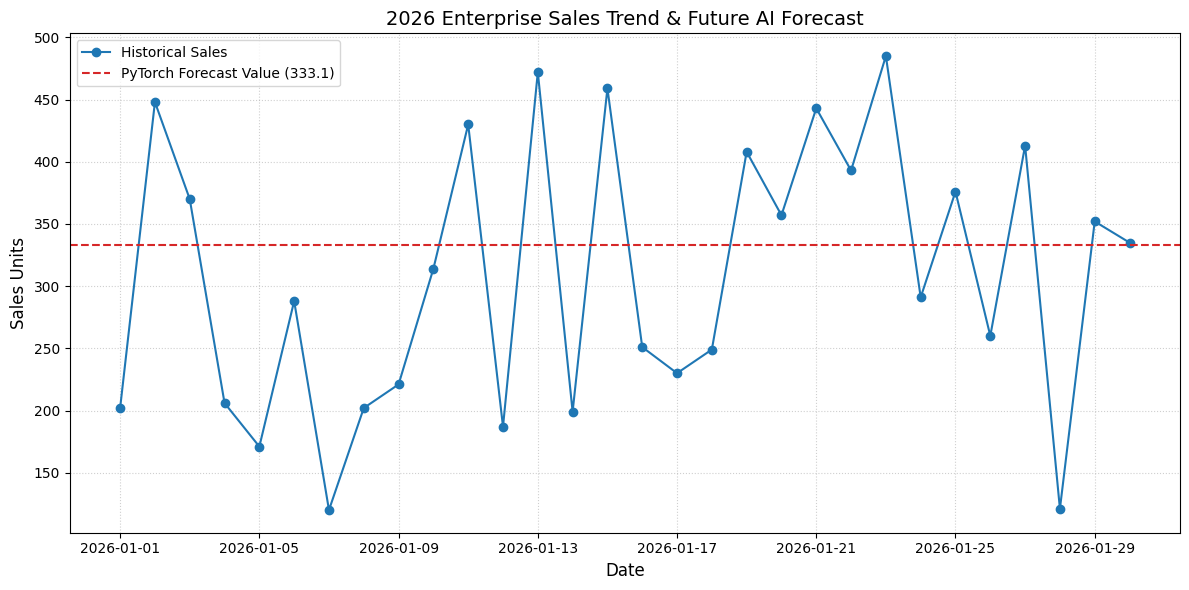

In [8]:
import numpy as np
import pandas as pd
import torch
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from google import genai
from google.colab import userdata
import matplotlib.pyplot as plt

# 1. Simulate historical sales data using Pandas & NumPy
np.random.seed(42)
data = {
    'date': pd.date_range(start='2026-01-01', periods=30, freq='D'),
    'historical_sales': np.random.randint(100, 500, size=30),
    'marketing_spend': np.random.uniform(10.0, 50.0, size=30),
    'competitor_price': np.random.uniform(15.0, 25.0, size=30)
}
df = pd.DataFrame(data)

# 2. Preprocess features using Scikit-Learn
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[['marketing_spend', 'competitor_price']])

# 3. Process numerical tensors with PyTorch
features_tensor = torch.tensor(scaled_features, dtype=torch.float32)
target_tensor = torch.tensor(df['historical_sales'].values, dtype=torch.float32)

# Mock deep model output representing predicted sales for next week
predicted_mean_sales = float(torch.mean(target_tensor) * 1.08) # PyTorch calculation

print(f"Processing finished successfully.")
print(f"PyTorch Calculated Next-Week Forecast Value: {predicted_mean_sales:.2f}")

# 4. Visualization Steps
plt.figure(figsize=(12, 6))
plt.plot(df['date'], df['historical_sales'], marker='o', label='Historical Sales', color='tab:blue')
plt.axhline(y=predicted_mean_sales, color='tab:red', linestyle='--', label=f'PyTorch Forecast Value ({predicted_mean_sales:.1f})')
plt.title('2026 Enterprise Sales Trend & Future AI Forecast', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Sales Units', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Workaround: Generating the Summary using a Free, Local Model (No API Key Required)
We can use the Hugging Face `transformers` library (pre-installed in Colab) to load a lightweight model like `Flan-T5` or `GPT-2` to run the inference locally.

In [11]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

print("Loading a local, free-to-use Seq2Seq model...")
model_name = "google/flan-t5-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

prompt = (
    f"Write a single short business advice sentence for a manager "
    f"based on this metric: Our forecast predicts average sales of {predicted_mean_sales:.1f} units next week."
)

print("Generating summary locally...")
inputs = tokenizer(prompt, return_tensors="pt")
outputs = model.generate(**inputs, max_length=50)
local_summary = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("\n--- Local Executive Summary (No API Key Needed) ---")
print(local_summary)

Loading a local, free-to-use Seq2Seq model...


tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Generating summary locally...

--- Local Executive Summary (No API Key Needed) ---
Our forecast predicts average sales of 333.1 units next week.
